In [1]:
from google.colab import drive
import os
import sys

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Arahkan direktori kerja aktif ke dalam folder 'notebook' Anda di Drive
os.chdir('/content/drive/MyDrive/Computer Vision/simuteh-2330511084/notebook')

# 3. Masukkan folder 'src' ke dalam sys.path secara mutlak (absolute path)
src_path = '/content/drive/MyDrive/Computer Vision/simuteh-2330511084/src'
if src_path not in sys.path:
    sys.path.append(src_path)

print("Berhasil! Direktori saat ini:", os.getcwd())

Mounted at /content/drive
Berhasil! Direktori saat ini: /content/drive/MyDrive/Computer Vision/simuteh-2330511084/notebook


## Bagian 1. Gradien Citra dan Operator Tepi

In [2]:
import numpy as np
A = np.array([[52, 55, 180], [50, 58, 185], [54, 60, 190]], np.float32)
kx_s = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)
kx_p = np.array([[-1, 0, 1]] * 3, np.float32)
lap  = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], np.float32)
for nm, kx in [("Sobel", kx_s), ("Prewitt", kx_p)]:
    gx = float((A * kx).sum()); gy = float((A * kx.T).sum())
    print(nm, "Gx =", gx, "Gy =", gy, "|G| =", round(np.hypot(gx, gy), 2),
          "|Gx|+|Gy| =", abs(gx) + abs(gy), "theta =", round(np.degrees(np.arctan2(gy, gx)), 2))
print("Laplacian =", float((A * lap).sum()))

Sobel Gx = 534.0 Gy = 22.0 |G| = 534.45 |Gx|+|Gy| = 556.0 theta = 2.36
Prewitt Gx = 399.0 Gy = 17.0 |G| = 399.36 |Gx|+|Gy| = 416.0 theta = 2.44
Laplacian = 118.0


### Langkah 1.1 Persiapan dan gradien Sobel

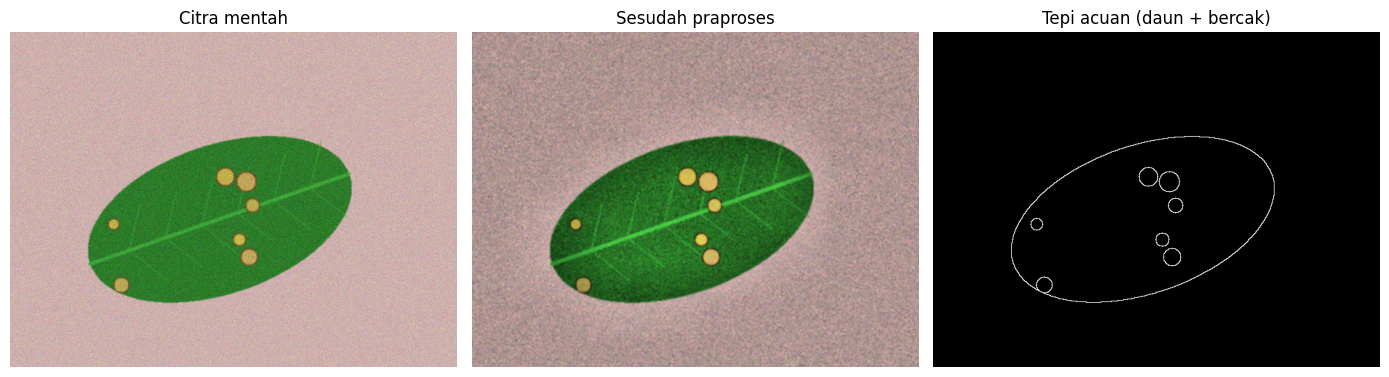

In [3]:
import sys, json
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)

PARAM = json.load(open("../hasil/param_praproses.json"))   # hasil Evaluasi P1-P4
label = pd.read_csv("../data/sintetis/label.csv")

def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

img, md, mb = muat("teh_041.png")
pra = praproses(img, PARAM)
acuan = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
tampil([img, pra, acuan], ["Citra mentah", "Sesudah praproses", "Tepi acuan (daun + bercak)"])

## Langkah 1.2 Gradien Sobel manual: Gx, Gy, magnitudo, dan arah Kode 1.2

selisih maks gx manual vs cv2.Sobel: 0.0
magnitudo maks: 644.2


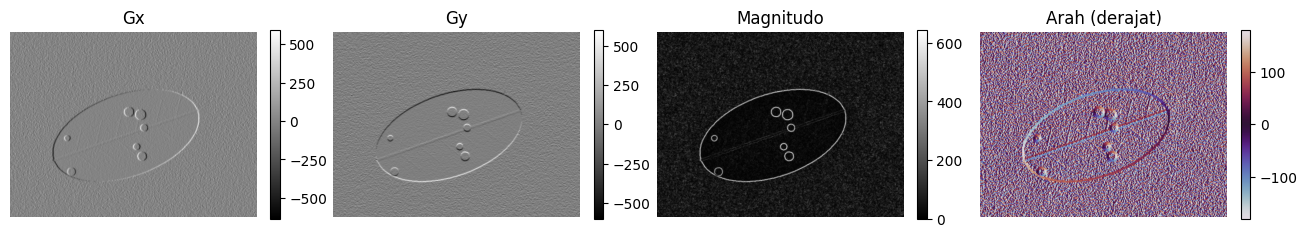

In [4]:
g = pra[:, :, 2].astype(np.float32)               # kanal R hasil praproses
kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)
ky = kx.T
gx = cv2.filter2D(g, cv2.CV_32F, kx)              # turunan arah x (tepi vertikal)
gy = cv2.filter2D(g, cv2.CV_32F, ky)              # turunan arah y (tepi horizontal)
mag = np.sqrt(gx ** 2 + gy ** 2)
arah = np.degrees(np.arctan2(gy, gx))

# bandingkan dengan fungsi pustaka
gx_cv = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
print("selisih maks gx manual vs cv2.Sobel:", np.abs(gx - gx_cv).max())
print("magnitudo maks:", mag.max().round(1))

plt.figure(figsize=(16, 3.6))
for i, (c, jd) in enumerate([(gx, "Gx"), (gy, "Gy"), (mag, "Magnitudo"), (arah, "Arah (derajat)")]):
    plt.subplot(1, 4, i + 1); plt.imshow(c, cmap="twilight" if i == 3 else "gray")
    plt.title(jd); plt.axis("off"); plt.colorbar(fraction=0.035)
plt.savefig("../hasil/p5_gradien_sobel.png", dpi=120, bbox_inches="tight")

### Langkah 1.3 Empat operator pada satu citra (Kode 1.3)

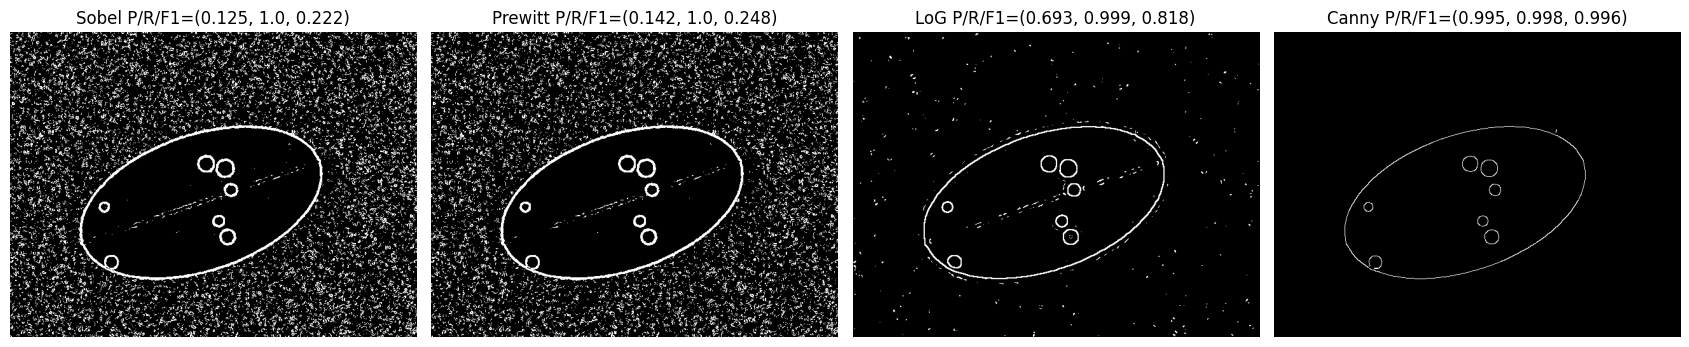

In [5]:
def tepi_sobel(g, T=100):
    g = g.astype(np.float32)
    m = np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1))
    return ((m > T) * 255).astype(np.uint8)

def tepi_prewitt(g, T=75):
    kx = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32)
    g = g.astype(np.float32)
    m = np.hypot(cv2.filter2D(g, -1, kx), cv2.filter2D(g, -1, kx.T))
    return ((m > T) * 255).astype(np.uint8)

def tepi_log(g, sigma=3.0, frac=0.2):
    """Laplacian of Gaussian: tepi = perlintasan nol yang cukup kuat."""
    L = cv2.Laplacian(cv2.GaussianBlur(g.astype(np.float32), (0, 0), sigma), cv2.CV_32F)
    mn, mx = cv2.erode(L, np.ones((3, 3))), cv2.dilate(L, np.ones((3, 3)))
    return (((mn < 0) & (mx > 0) & (mx - mn > frac * np.abs(L).max())) * 255).astype(np.uint8)

def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

metode = {"Sobel": tepi_sobel, "Prewitt": tepi_prewitt, "LoG": tepi_log, "Canny": tepi_canny}
g = pra[:, :, 2]
hasil = {nm: f(g) for nm, f in metode.items()}
tampil(list(hasil.values()), [f"{nm} P/R/F1={skor_tepi(e, acuan)}" for nm, e in hasil.items()],
       ukuran=(17, 3.6))
plt.savefig("../hasil/p5_empat_operator.png", dpi=120, bbox_inches="tight")

### KodLangkah 1.4 Perbandingan menyeluruh Kode 1.4

In [6]:
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    for sumber, im in [("mentah", img), ("praproses", praproses(img, PARAM))]:
        for kanal, g in [("Gray", cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)), ("R", im[:, :, 2])]:
            for nm, f in metode.items():
                p, r, f1 = skor_tepi(f(g), ac)
                baris.append([d.kondisi_cahaya, sumber, kanal, nm, p, r, f1])
tabel_tepi = pd.DataFrame(baris, columns=["kondisi", "sumber", "kanal", "metode", "P", "R", "F1"])
ringkas = tabel_tepi.groupby(["sumber", "kanal", "metode"])[["P", "R", "F1"]].mean().round(3)
print(ringkas)
tabel_tepi.to_csv("../hasil/p5_tabel_tepi.csv", index=False)

                             P      R     F1
sumber    kanal metode                      
mentah    Gray  Canny    0.766  0.752  0.758
                LoG      0.628  0.998  0.761
                Prewitt  0.799  0.953  0.859
                Sobel    0.761  0.963  0.839
          R     Canny    0.983  0.990  0.986
                LoG      0.905  0.998  0.944
                Prewitt  0.538  0.997  0.651
                Sobel    0.473  0.997  0.588
praproses Gray  Canny    0.664  0.954  0.777
                LoG      0.534  0.998  0.686
                Prewitt  0.536  0.997  0.685
                Sobel    0.500  0.997  0.651
          R     Canny    0.955  0.990  0.971
                LoG      0.827  0.998  0.892
                Prewitt  0.416  0.998  0.554
                Sobel    0.366  0.998  0.504


### Langkah 1.5 KERJAKAN SENDIRI

metode          Sobel  Prewitt    LoG  Canny
kondisi                                     
normal          0.372    0.412  0.940  0.969
gelap           0.472    0.523  0.957  0.967
terang          0.470    0.526  0.899  0.960
kontras_rendah  0.581    0.637  0.724  0.987
bayangan        0.625    0.671  0.941  0.973


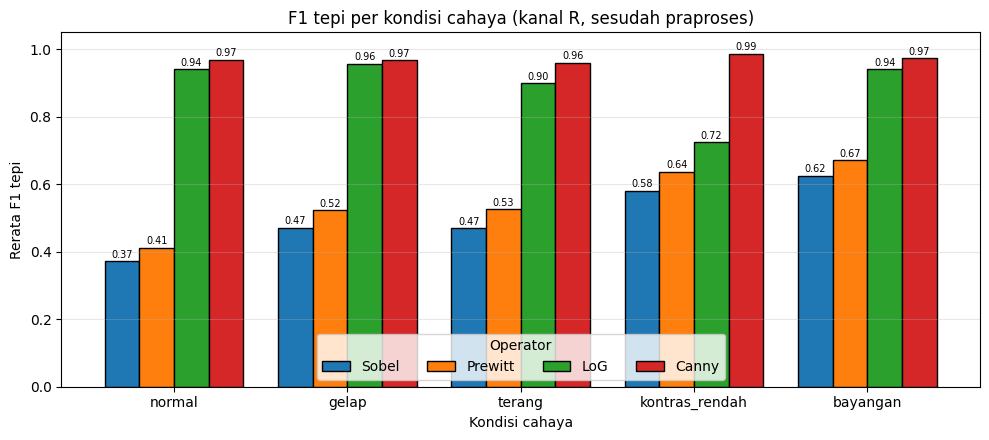

In [7]:
# Langkah 1.5: grafik batang F1 per kondisi cahaya, kanal R sesudah praproses
urutan = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
sub = tabel_tepi[(tabel_tepi.sumber == "praproses") & (tabel_tepi.kanal == "R")]
f1_kond = (sub.pivot_table(index="kondisi", columns="metode", values="F1", aggfunc="mean")
              .reindex([k for k in urutan if k in sub.kondisi.unique()])[["Sobel", "Prewitt", "LoG", "Canny"]])
print(f1_kond.round(3))

ax = f1_kond.plot(kind="bar", figsize=(10, 4.5), width=0.8, edgecolor="black")
ax.set_ylabel("Rerata F1 tepi"); ax.set_xlabel("Kondisi cahaya")
ax.set_title("F1 tepi per kondisi cahaya (kanal R, sesudah praproses)")
ax.set_ylim(0, 1.05); ax.legend(title="Operator", ncol=4, loc="lower center")
plt.xticks(rotation=0); ax.grid(axis="y", alpha=0.3)
for cont in ax.containers:                       # tampilkan angka di atas batang
    ax.bar_label(cont, fmt="%.2f", fontsize=7, padding=1)
plt.tight_layout()
plt.savefig("../hasil/p5_f1_kondisi.png", dpi=150, bbox_inches="tight")
plt.show()

### Pertanyaan Analisis Bagian 1 (jawab di laporan dengan kode P1.1 dst.)
- **P1.1** Mengapa |Gx| jauh lebih besar dari |Gy|? Hubungan arah gradien dengan arah tepi; tunjukkan pada panel arah Kode 1.2.
- **P1.2** Mengapa magnitudo Sobel > Prewitt untuk tepi yang sama? Akibatnya bila T sama dipakai untuk keduanya?
- **P1.3** Berdasarkan Tabel 6, kanal mana yang memberi F1 lebih tinggi per operator? Kaitkan dengan KB per kanal (`hasil/b2_kb_kanal.csv`).
- **P1.4** Apakah praproses menaikkan F1 untuk semua operator dan kanal? Kombinasi mana praproses justru menurunkan presisi/recall, dan mengapa?
- **P1.5** Cara kerja zero crossing pada LoG; mengapa LoG tanpa ambang memadai menghasilkan banyak tepi palsu?

## Bagian 2. Algoritma Canny dan Keputusan Pemakaian Tepi

### Langkah 2.2 Pengaruh sigma dan ambang  (Kode 2.1)

In [8]:
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    g = praproses(img, PARAM)[:, :, 2]
    ad, ab = tepi_acuan(md), tepi_acuan(mb)
    ac = cv2.bitwise_or(ad, ab)
    for sigma in [0, 1.0, 2.0]:
        for lo, hi in [(30, 90), (50, 150), (100, 200)]:
            e = tepi_canny(g, lo, hi, sigma)
            p, r, f1 = skor_tepi(e, ac)
            r_bercak = skor_tepi(e, ab)[1]          # recall khusus tepi bercak
            baris.append([d.kelas, sigma, f"{lo}/{hi}", p, r, f1, r_bercak])
canny = pd.DataFrame(baris, columns=["kelas", "sigma", "ambang", "P", "R", "F1", "R_bercak"])
print(canny.groupby(["sigma", "ambang"])[["P", "R", "F1", "R_bercak"]].mean().round(3))
print(canny.pivot_table(index=["sigma", "ambang"], columns="kelas", values="R_bercak").round(3))

                   P      R     F1  R_bercak
sigma ambang                                
0.0   100/200  0.474  0.994  0.585     0.979
      30/90    0.018  0.997  0.035     0.988
      50/150   0.068  0.995  0.120     0.984
1.0   100/200  0.973  0.993  0.983     0.965
      30/90    0.183  0.994  0.273     0.976
      50/150   0.852  0.994  0.909     0.974
2.0   100/200  0.789  0.787  0.788     0.734
      30/90    0.955  0.990  0.971     0.947
      50/150   0.984  0.984  0.984     0.903
kelas          berat  ringan
sigma ambang                
0.0   100/200  0.980   0.978
      30/90    0.989   0.987
      50/150   0.981   0.986
1.0   100/200  0.977   0.953
      30/90    0.980   0.973
      50/150   0.979   0.968
2.0   100/200  0.743   0.726
      30/90    0.958   0.936
      50/150   0.932   0.874


**Tabel 7** - salin ke laporan: kolom Sigma, Ambang, P, R, F1, R bercak (berat), R bercak (ringan) untuk 9 kombinasi.

### Langkah 2.3 Ambang otomatis  (Kode 2.2)

In [9]:
def canny_otomatis(g, s=0.33):
    """Ambang dari median intensitas: bawah = (1-s) x median, atas = (1+s) x median."""
    v = np.median(g)
    return cv2.Canny(g, int(max(0, (1 - s) * v)), int(min(255, (1 + s) * v)))

baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra_ = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        baris.append([d.kondisi_cahaya, kanal, "otomatis", skor_tepi(canny_otomatis(g), ac)[2], np.median(g)])
        baris.append([d.kondisi_cahaya, kanal, "tetap 30/90", skor_tepi(tepi_canny(g), ac)[2], np.median(g)])
auto = pd.DataFrame(baris, columns=["kondisi", "kanal", "ambang", "F1", "median"])
print(auto.pivot_table(index=["kanal", "ambang"], columns="kondisi", values="F1").round(3))
print(auto.groupby(["kanal", "kondisi"])["median"].mean().round(1))

kondisi            bayangan  gelap  kontras_rendah  normal  terang
kanal ambang                                                      
Gray  otomatis        0.535  0.626           0.772   0.681   0.829
      tetap 30/90     0.733  0.743           0.909   0.746   0.754
R     otomatis        0.457  0.599           0.723   0.597   0.909
      tetap 30/90     0.973  0.967           0.987   0.969   0.960
kanal  kondisi       
Gray   bayangan          117.6
       gelap             139.5
       kontras_rendah    148.0
       normal            164.0
       terang            194.1
R      bayangan          123.5
       gelap             153.2
       kontras_rendah    151.9
       normal            175.6
       terang            199.2
Name: median, dtype: float64


### Langkah 2.4 KERJAKAN SENDIRI: perbaiki ambang otomatis
Tulis `canny_persentil(g, q, rasio=0.4, sigma=2.0)` yang: (1) menghaluskan citra dengan Gaussian, (2) menghitung magnitudo Sobel, (3) memakai **persentil ke-q** magnitudo sebagai ambang atas dan `rasio x ambang atas` sebagai ambang bawah, (4) memanggil `cv2.Canny`.  
Uji q = 90, 95, 98 pada kanal Gray dan R di setiap kondisi, bandingkan dengan Kode 2.2.

Petunjuk: `cv2.Canny` menerima `g` uint8, jadi pakai `cv2.GaussianBlur` pada `g` lalu hitung Sobel dari hasil blur; `np.percentile(mag, q)`.

In [10]:
# TODO (Langkah 2.4): tulis sendiri canny_persentil dan ujinya

### Langkah 2.5 Tepi pada daun sehat (Kode 2.3)

kanal            Gray      R
kondisi                     
bayangan        760.0    0.0
gelap           731.0    0.0
kontras_rendah   98.5    0.0
normal          874.5  185.2
terang          848.5  337.0


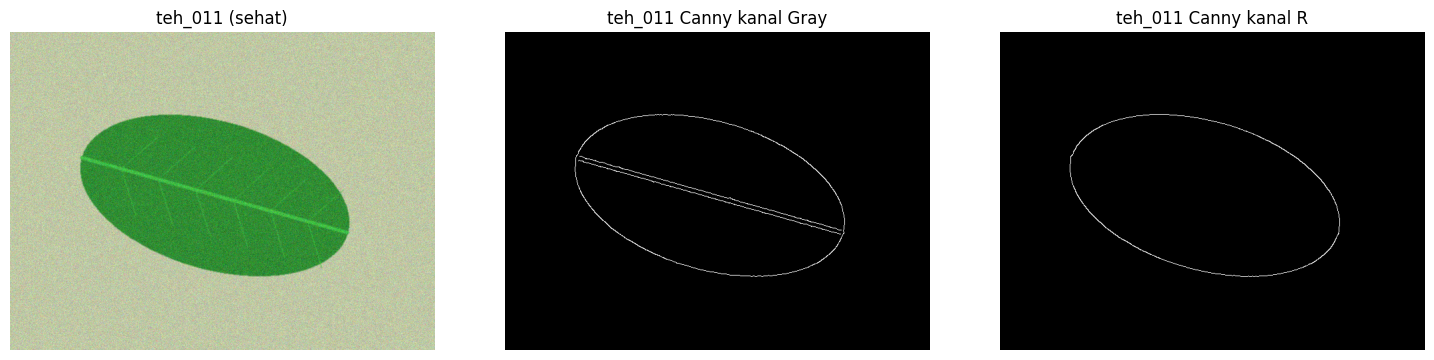

In [11]:
baris, panel, judul = [], [], []
for _, d in label[label.kelas == "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    dalam = cv2.erode(md, np.ones((7, 7), np.uint8)) > 0      # bagian dalam daun
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        e = tepi_canny(g)
        baris.append([d.kondisi_cahaya, kanal, int(((e > 0) & dalam).sum())])
        if d.nama_file == "teh_011.png":
            panel.append(e); judul.append(f"teh_011 Canny kanal {kanal}")
sehat = pd.DataFrame(baris, columns=["kondisi", "kanal", "piksel_tepi_di_dalam_daun"])
print(sehat.pivot_table(index="kondisi", columns="kanal", values="piksel_tepi_di_dalam_daun").round(1))
tampil([muat("teh_011.png")[0]] + panel, ["teh_011 (sehat)"] + judul, ukuran=(15, 3.6))

### Langkah 2.6 KERJAKAN SENDIRI: Tabel 8 keputusan
Isi dengan merujuk bukti Bagian 1 dan 2 (nomor tabel/gambar):

| Keperluan | Dipakai? (ya/tidak) | Operator dan parameter | Bukti |
|---|---|---|---|
| Menemukan batas daun | | | |
| Menemukan batas bercak | | | |
| Mengisi wilayah bercak (segmentasi) | | | |
| Fitur bentuk bercak (P9) | | | |

### Langkah 2.7 Checkpoint
```
git add .
git commit -m "P5: deteksi tepi (Sobel, Prewitt, LoG, Canny) dan keputusan pemakaian tepi"
git tag v0.2-tepi
git push --tags
```

### Pertanyaan Analisis Bagian 2
- **P2.1** Mengapa NMS membandingkan dengan tetangga searah gradien (bukan searah tepi)? Mengapa hysteresis dua ambang, dan mengapa piksel bernilai 90 pada soal (b) dibuang walau > ambang bawah?
- **P2.2** Kombinasi Tabel 7 dengan F1 tertinggi; apakah juga terbaik untuk kelas ringan? Trade-off meredam derau vs mempertahankan bercak kecil.
- **P2.3** Pada kontras rendah kanal Gray, ambang median dan 30/90 gagal tetapi kanal R tidak. Hitung ambang otomatis dari median keluaran Kode 2.2, bandingkan dengan besar gradien di tepi daun. Mengapa ambang dari intensitas tidak cocok untuk Canny?
- **P2.4** Mengapa ambang persentil magnitudo lebih tahan perubahan kontras? Mengapa q berkaitan dengan proporsi piksel tepi?
- **P2.5** Mengapa tulang daun sehat terdeteksi di kanal Gray tetapi tidak di kanal R? Artinya bagi pemilihan kanal SIMUTEH?
- **P2.6** Jelaskan keputusan Tabel 8. Mengapa tepi saja belum cukup untuk persentase luas bercak? Kaitkan dengan kebutuhan pengguna nomor 2 dan 4.